# 01 Data Exploration: DGM4

Exploratory analysis of the DGM4 news image-caption dataset ([paper](https://arxiv.org/abs/2304.02556), [Hugging Face](https://huggingface.co/datasets/rshaojimmy/DGM4)).

**Goals**
1. Understand the structure of each split and what each column means
2. Profile the manipulation labels and how they map to our two prediction targets (image manipulated, text manipulated)
3. Find data-quality issues that `02_data_cleaning` must handle
4. Check the face boxes and captions for signals and leakage risks before feature engineering

Findings are summarised at the end of the notebook.

## 1. Setup

In [1]:
import zipfile
from functools import lru_cache
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

from datasets import load_dataset
from huggingface_hub import hf_hub_download, try_to_load_from_cache
from PIL import Image as PILImage

REPO_ID = "rshaojimmy/DGM4"
RANDOM_STATE = 4012

# Image archives are 1-10GB each. Leave False to only show images from archives already downloaded.
DOWNLOAD_ARCHIVES = False

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

In [2]:
# Helpers to load images from the zipped Hugging Face archives
def archive_for(image_path):
    # "DGM4/manipulation/infoswap/x.jpg" -> "manipulation/infoswap.zip"
    path_parts = image_path.removeprefix("DGM4/").split("/")
    return "/".join(path_parts[:2]) + ".zip"


def is_archive_cached(archive_name):
    return isinstance(
        try_to_load_from_cache(REPO_ID, archive_name, repo_type="dataset"), str
    )


@lru_cache(maxsize=None)
def open_archive(archive_name):
    archive_path = hf_hub_download(REPO_ID, archive_name, repo_type="dataset")
    archive = zipfile.ZipFile(archive_path)
    # Index members by path without the archive's top-level folder, so lookups are O(1)
    index = {name.split("/", 1)[-1]: name for name in archive.namelist()}
    return archive, index


def load_hf_image(image_path):
    archive_name = archive_for(image_path)
    archive, index = open_archive(archive_name)
    target_name = "/".join(image_path.removeprefix("DGM4/").split("/")[2:])
    if target_name not in index:
        raise FileNotFoundError(f"{target_name} was not found in {archive_name}")
    return PILImage.open(BytesIO(archive.read(index[target_name]))).convert("RGB")

## 2. Load Datasets

In [3]:
ds = load_dataset(REPO_ID)
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 208184
    })
    validation: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 22126
    })
    test: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 50705
    })
})

In [4]:
split_dfs = {split: ds[split].to_pandas() for split in ["train", "validation", "test"]}
train_df = split_dfs["train"]
val_df = split_dfs["validation"]
test_df = split_dfs["test"]

train_df.head()

,id,text,image,fake_cls,fake_text_pos,mtcnn_boxes,fake_image_box
0,995762,A Victorian court decided on Friday that former AFL player agent Ricky Nixon...,DGM4/manipulation/infoswap/995762-043201-infoswap.jpg,face_swap,[],"[[178, 35, 226, 99], [357, 39, 401, 95], [58, 107, 79, 137]]","[178, 35, 226, 99]"
1,69406,What s the biggest surprise from the JPMorgan Senate report,DGM4/manipulation/simswap/69406-106968-simswap.jpg,face_swap,[],"[[159, 18, 208, 79], [259, 44, 280, 70]]","[159, 18, 208, 79]"
2,1486322,Chanan Reitblat told the court said felt violated and devastated,DGM4/manipulation/simswap/1486322-004604-simswap.jpg,face_swap,[],"[[185, 51, 328, 237], [388, 118, 464, 229], [71, 94, 143, 186]]","[388, 118, 464, 229]"
3,45310,David Oyelowo left and Michael Keaton,DGM4/origin/washington_post/0065/855.jpg,orig,[],"[[151, 34, 184, 78], [204, 35, 234, 77]]",[]
4,335277,Connecticut Governor Dannel P Malloy and First Lady Michelle Obama chat befo...,DGM4/manipulation/infoswap/335277-177841-infoswap.jpg,face_swap,[],"[[122, 62, 161, 126], [169, 74, 209, 124], [321, 94, 357, 148]]","[321, 94, 357, 148]"


### Column dictionary

| Column | Type | Description | Use as model input? |
|---|---|---|---|
| `id` | int | ID of the source news article. An original pair and all its manipulated versions share the same `id` | No (grouping key only) |
| `text` | str | News caption, possibly manipulated | Yes |
| `image` | str | Path to the image inside the HF archives, possibly manipulated | Yes (the image itself) |
| `mtcnn_boxes` | list of `[x1, y1, x2, y2]` | Faces detected by MTCNN | Yes |
| `fake_cls` | str | Manipulation type(s), e.g. `orig`, `face_swap`, `face_attribute&text_swap` | **No, label** |
| `fake_image_box` | `[x1, y1, x2, y2]` or `[]` | Box of the manipulated face | **No, label** |
| `fake_text_pos` | list of int | Word positions in `text` that were manipulated | **No, label** |

In [5]:
split_summary = pd.DataFrame({
    split: {
        "rows": len(df),
        "unique_ids": df["id"].nunique(),
        "missing_values": int(df.isna().sum().sum()),
        "empty_captions": int((df["text"].str.strip() == "").sum()),
    }
    for split, df in split_dfs.items()
}).T

split_summary

,rows,unique_ids,missing_values,empty_captions
train,208184,56894,0,0
validation,22126,7975,0,0
test,50705,18360,0,0


In [ ]:
# The official splits must not share source articles
train_ids, val_ids, test_ids = (set(df["id"]) for df in split_dfs.values())

print("Train & Validation:", len(train_ids & val_ids))
print("Train & Test:", len(train_ids & test_ids))
print("Validation & Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


## 3. Manipulation Labels

`fake_cls` combines up to one image manipulation and one text manipulation with `&`. The four techniques, as defined in the DGM4 paper:

| Modality | Type | What changes | Generator (image folder) |
|---|---|---|---|
| Image | `face_swap` | The main person's face is replaced with another person's face | `infoswap`, `simswap` |
| Image | `face_attribute` | The main person keeps their identity, but their **facial expression** is edited (e.g. smiling → angry) | `StyleCLIP`, `HFGI` |
| Text | `text_swap` | The whole caption is replaced with a caption from a different article about the **same person** | (image unchanged) |
| Text | `text_attribute` | Sentiment-bearing words are flipped to the opposite sentiment, keeping the rest of the caption | (image unchanged) |

In [7]:
def add_label_columns(df):
    df["image_fake"] = df["fake_cls"].str.contains("face").astype(int)
    df["text_fake"] = df["fake_cls"].str.contains("text").astype(int)
    df["is_fake"] = (df["fake_cls"] != "orig").astype(int)
    df["manipulation_group"] = np.select(
        [df["image_fake"].eq(1) & df["text_fake"].eq(1), df["image_fake"].eq(1), df["text_fake"].eq(1)],
        ["Both image and text", "Image only", "Text only"],
        default="Original",
    )
    # Folder after "manipulation/" names the image generator; "origin/<publisher>" for untouched images
    path_parts = df["image"].str.split("/")
    df["image_source"] = path_parts.str[1] + "/" + path_parts.str[2]
    return df


for df in split_dfs.values():
    add_label_columns(df)

train_df[["fake_cls", "image_fake", "text_fake", "manipulation_group", "image_source"]].drop_duplicates("fake_cls")

,fake_cls,image_fake,text_fake,manipulation_group,image_source
0,face_swap,1,0,Image only,manipulation/infoswap
3,orig,0,0,Original,origin/washington_post
9,face_attribute&text_swap,1,1,Both image and text,manipulation/StyleCLIP
11,face_attribute,1,0,Image only,manipulation/HFGI
12,text_swap,0,1,Text only,origin/bbc
25,face_swap&text_attribute,1,1,Both image and text,manipulation/infoswap
84,text_attribute,0,1,Text only,origin/guardian
101,face_swap&text_swap,1,1,Both image and text,manipulation/simswap
236,face_attribute&text_attribute,1,1,Both image and text,manipulation/HFGI


In [8]:
class_distribution = pd.concat(
    {split: df["fake_cls"].value_counts(normalize=True) for split, df in split_dfs.items()},
    axis=1,
).mul(100).round(2)

group_distribution = pd.concat(
    {split: df["manipulation_group"].value_counts(normalize=True) for split, df in split_dfs.items()},
    axis=1,
).mul(100).round(2)

display(class_distribution)
display(group_distribution)

,train,validation,test
fake_cls,,,
orig,50.00,33.77,33.28
face_swap,16.19,21.64,20.74
face_attribute,13.70,18.07,17.59
text_swap,6.62,8.56,9.77
face_swap&text_swap,4.00,5.26,5.79
face_attribute&text_swap,3.36,4.36,4.99
text_attribute,2.89,3.73,3.89
face_swap&text_attribute,1.75,2.41,2.20
face_attribute&text_attribute,1.49,2.20,1.75


,train,validation,test
manipulation_group,,,
Original,50.00,33.77,33.28
Image only,29.89,39.71,38.33
Both image and text,10.61,14.22,14.73
Text only,9.51,12.29,13.66


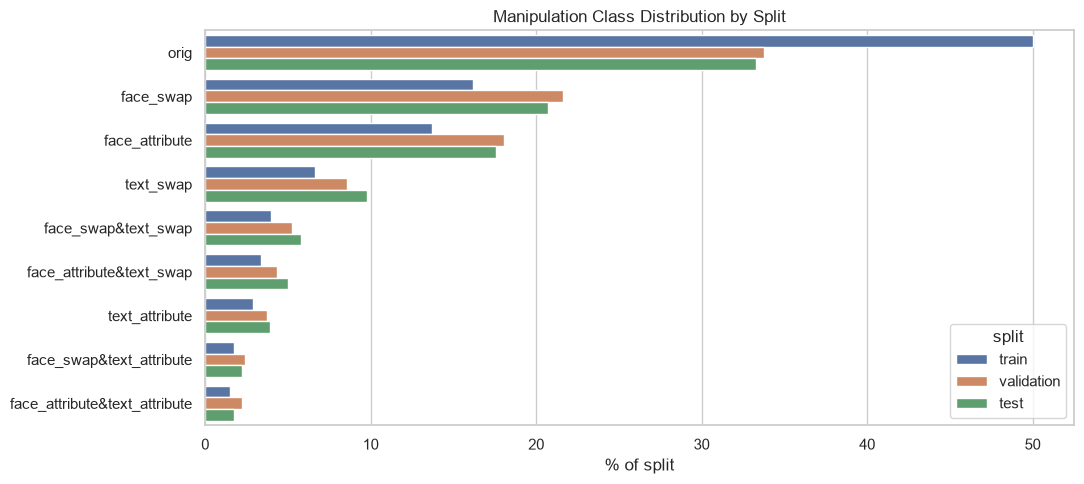

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
(
    class_distribution
    .reset_index(names="fake_cls")
    .melt(id_vars="fake_cls", var_name="split", value_name="percent")
    .pipe(lambda d: sns.barplot(data=d, y="fake_cls", x="percent", hue="split", ax=ax))
)
ax.set_title("Manipulation Class Distribution by Split")
ax.set_xlabel("% of split")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Train is 50% `orig`, while validation and test are about 33%. Section 4 shows why: most genuine pairs in train appear twice.

In [10]:
# Which generators produced the manipulated images, and which publishers the originals come from
source_counts = (
    train_df
    .groupby(["image_source", "image_fake"])
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(["image_fake", "rows"], ascending=[False, False])
)
source_counts

,image_source,image_fake,rows
2,manipulation/infoswap,1,30237
0,manipulation/HFGI,1,19432
1,manipulation/StyleCLIP,1,19193
3,manipulation/simswap,1,15433
5,origin/guardian,0,65774
4,origin/bbc,0,23352
6,origin/usa_today,0,19410
7,origin/washington_post,0,15353


## 4. IDs and Repeated Genuine Pairs

Each `id` is one source article. Its rows are the original pair plus manipulated versions built from it.

In [11]:
rows_per_id = pd.concat(
    {split: df.groupby("id").size().value_counts().sort_index() for split, df in split_dfs.items()},
    axis=1,
).fillna(0).astype(int)
rows_per_id.index.name = "rows per id"
rows_per_id

,train,validation,test
rows per id,,,
1,4246,714,1993
2,3730,1517,3176
3,14547,4611,10443
4,20975,1120,2709
5,11463,13,39
6,1909,0,0
7,24,0,0


In [12]:
# Example: one article with several versions
example_id = train_df.groupby("id").size().idxmax()
train_df.loc[train_df["id"] == example_id, ["id", "fake_cls", "image", "text"]]

,id,fake_cls,image,text
32838,122531,face_swap,DGM4/manipulation/infoswap/122531-150634-infoswap.jpg,Murphy is only the fifth American to win both the 100 and 200 backstroke in ...
53095,122531,text_swap,DGM4/origin/washington_post/0515/492.jpg,Mr Murphy was met by protestors as he arrived for the Scottish Labour nation...
94458,122531,orig,DGM4/origin/washington_post/0515/492.jpg,Murphy is only the fifth American to win both the 100 and 200 backstroke in ...
95896,122531,text_attribute,DGM4/origin/washington_post/0515/492.jpg,Murphy is only the fifth American to lose the 100 and 200 backstroke in the ...
101433,122531,orig,DGM4/origin/washington_post/0515/492.jpg,Murphy is only the fifth American to win both the 100 and 200 backstroke in ...
128981,122531,face_attribute,DGM4/manipulation/StyleCLIP/122531-StyleCLIP.jpg,Murphy is only the fifth American to win both the 100 and 200 backstroke in ...
129464,122531,orig,DGM4/origin/washington_post/0515/492.jpg,Murphy is only the fifth American to win both the 100 and 200 backstroke in ...


In [13]:
dup_cols = ["id", "text", "image"]

duplicate_summary = pd.DataFrame({
    split: {
        "orig_rows": int((df["fake_cls"] == "orig").sum()),
        "unique_orig_pairs": int(df.loc[df["fake_cls"] == "orig", dup_cols].drop_duplicates().shape[0]),
        "duplicate_rows_all_classes": int(df.duplicated(dup_cols + ["fake_cls"]).sum()),
    }
    for split, df in split_dfs.items()
}).T
duplicate_summary["duplicate_orig_rows"] = duplicate_summary["orig_rows"] - duplicate_summary["unique_orig_pairs"]
duplicate_summary

,orig_rows,unique_orig_pairs,duplicate_rows_all_classes,duplicate_orig_rows
train,104092,53077,51015,51015
validation,7473,7473,0,0
test,16876,16876,0,0


In [14]:
# Class mix of train once the repeated genuine pairs are removed
train_dedup = train_df.drop_duplicates(dup_cols + ["fake_cls"])
print("Train rows after dedup:", len(train_dedup))
train_dedup["manipulation_group"].value_counts(normalize=True).mul(100).round(2)

Train rows after dedup: 157169


manipulation_group
Image only             39.59
Original               33.77
Both image and text    14.05
Text only              12.60
Name: proportion, dtype: float64

In [15]:
# Do manipulated versions keep the original's face boxes? If so, mtcnn_boxes were computed on the
# original image and cannot leak the label.
boxes_as_str = train_df["mtcnn_boxes"].apply(lambda boxes: str([list(b) for b in boxes]))
boxes_per_id = boxes_as_str.groupby(train_df["id"]).nunique()
print(f"IDs whose rows all share identical mtcnn_boxes: {(boxes_per_id == 1).mean():.1%}")

IDs whose rows all share identical mtcnn_boxes: 100.0%


## 5. Captions

In [16]:
for df in split_dfs.values():
    df["word_count"] = df["text"].str.split().str.len()

train_df.groupby("fake_cls")["word_count"].describe().round(1).sort_values("mean")

,count,mean,std,min,25%,50%,75%,max
fake_cls,,,,,,,,
face_swap&text_attribute,3649.0,15.3,5.4,5.0,11.0,15.0,19.0,30.0
face_attribute&text_attribute,3108.0,15.5,5.4,5.0,11.0,15.0,19.0,30.0
text_attribute,6009.0,15.9,5.7,5.0,12.0,15.0,20.0,30.0
face_attribute,28513.0,16.8,5.9,5.0,12.0,16.0,21.0,30.0
face_swap,33704.0,16.8,5.9,5.0,12.0,16.0,21.0,30.0
orig,104092.0,16.8,5.8,5.0,12.0,16.0,21.0,30.0
face_attribute&text_swap,7004.0,18.6,5.8,5.0,14.0,18.0,23.0,30.0
face_swap&text_swap,8317.0,18.7,5.8,5.0,14.0,18.0,23.0,30.0
text_swap,13788.0,18.7,5.9,5.0,14.0,18.0,23.0,30.0


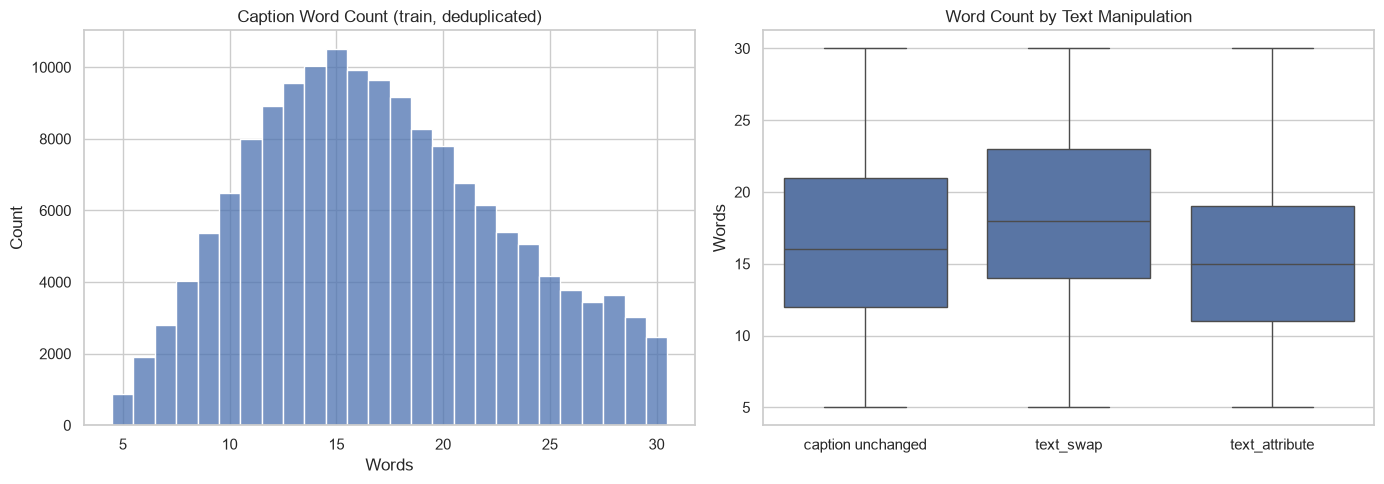

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_dedup.assign(word_count=train_dedup["text"].str.split().str.len()),
             x="word_count", discrete=True, ax=axes[0])
axes[0].set_title("Caption Word Count (train, deduplicated)")
axes[0].set_xlabel("Words")

text_label = np.select(
    [train_df["fake_cls"].str.contains("text_swap"), train_df["fake_cls"].str.contains("text_attribute")],
    ["text_swap", "text_attribute"],
    default="caption unchanged",
)
sns.boxplot(x=text_label, y=train_df["word_count"], ax=axes[1], showfliers=False)
axes[1].set_title("Word Count by Text Manipulation")
axes[1].set_xlabel("")
axes[1].set_ylabel("Words")

plt.tight_layout()
plt.show()

In [18]:
# How much of the caption is changed? fake_text_pos holds the indices of manipulated words.
text_manip = train_df[train_df["text_fake"] == 1].copy()
text_manip["text_type"] = np.where(text_manip["fake_cls"].str.contains("text_swap"), "text_swap", "text_attribute")
text_manip["n_fake_words"] = text_manip["fake_text_pos"].str.len()
text_manip["share_fake_words"] = text_manip["n_fake_words"] / text_manip["word_count"]

display(text_manip.groupby("text_type")[["n_fake_words", "share_fake_words"]].describe().round(2).T)

# Sanity check: captions not text-manipulated should have no manipulated positions
print("Non-text rows with fake_text_pos:", int((train_df.loc[train_df["text_fake"] == 0, "fake_text_pos"].str.len() > 0).sum()))

text_type               text_attribute  text_swap
n_fake_words     count        12766.00   29109.00
                 mean             1.53      11.85
                 std              0.78       4.55
                 min              1.00       1.00
                 25%              1.00       8.00
                 50%              1.00      12.00
                 75%              2.00      15.00
                 max             10.00      25.00
share_fake_words count        12766.00   29109.00
                 mean             0.11       0.63
                 std              0.07       0.11
                 min              0.03       0.04
                 25%              0.06       0.57
                 50%              0.09       0.64
                 75%              0.14       0.70
                 max              0.67       0.94

Non-text rows with fake_text_pos: 0


In [19]:
# Show which words were changed in a few text_attribute captions, next to the original caption of the same article
def highlight_fake_words(row):
    words = row["text"].split()
    fake_positions = set(row["fake_text_pos"].tolist())
    return " ".join(f"[{w}]" if i in fake_positions else w for i, w in enumerate(words))


orig_text = train_df[train_df["fake_cls"] == "orig"].drop_duplicates("id").set_index("id")["text"]
examples = text_manip[text_manip["text_type"] == "text_attribute"].sample(5, random_state=RANDOM_STATE)

for _, row in examples.iterrows():
    print("ORIGINAL:   ", orig_text.get(row["id"], "(not in train)"))
    print("MANIPULATED:", highlight_fake_words(row))
    print()

ORIGINAL:    VS Naipaul and Paul Theroux ended their animosity of 15 years with a handshake at the Hay festival
MANIPULATED: VS Naipaul and Paul Theroux [criticised] their animosity of 15 years with a handshake at the Hay festival

ORIGINAL:    Xi Jinping came to power vowing to tackle corruption and promote judicial fairness
MANIPULATED: Xi Jinping came to [face] [criticism] to tackle corruption and promote judicial [corruption]

ORIGINAL:    10000 people have signed an online petition calling for Tom Cleverley to be dropped from England s World Cup squad
MANIPULATED: 10000 people have signed an online petition calling for Tom Cleverley to be [welcomed] from England s World Cup squad

ORIGINAL:    Larry and Piper s relationship is sorely tested by her spell behind bars
MANIPULATED: Larry and Piper s [happiness] is [embraced] by her spell behind bars

ORIGINAL:    The Taliban s 14year insurgency against Afghan and Nato forces has claimed tens of thousands of civilian and military lives

## 6. Faces and Bounding Boxes

Boxes are `[x1, y1, x2, y2]` in pixels.

,train,validation,test
count,208184.00,22126.00,50705.00
mean,2.68,2.69,2.67
std,0.94,0.94,0.93
min,2.00,2.00,2.00
25%,2.00,2.00,2.00
50%,2.00,2.00,2.00
75%,3.00,3.00,3.00
max,5.00,5.00,5.00


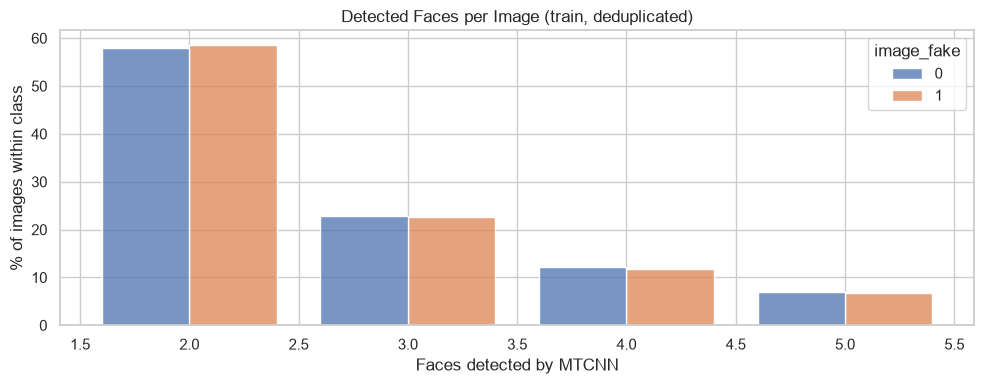

In [20]:
def box_area(box):
    return max(0, box[2] - box[0]) * max(0, box[3] - box[1])


for df in split_dfs.values():
    df["n_faces"] = df["mtcnn_boxes"].str.len()

face_counts = pd.concat(
    {split: df["n_faces"].describe() for split, df in split_dfs.items()}, axis=1
).round(2)
display(face_counts)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=train_dedup.assign(n_faces=train_dedup["mtcnn_boxes"].str.len()),
             x="n_faces", hue="image_fake", stat="percent", common_norm=False,
             discrete=True, multiple="dodge", shrink=0.8, ax=ax)
ax.set_title("Detected Faces per Image (train, deduplicated)")
ax.set_xlabel("Faces detected by MTCNN")
ax.set_ylabel("% of images within class")
plt.tight_layout()
plt.show()

In [21]:
# Sanity check: fake_image_box should be filled exactly when the image is manipulated
has_fake_box = train_df["fake_image_box"].str.len() == 4
pd.crosstab(train_df["image_fake"], has_fake_box, rownames=["image_fake"], colnames=["has fake_image_box"])

has fake_image_box,False,True
image_fake,,
0,123889,0
1,0,84295


In [22]:
# Is the manipulated face always the main (largest) face? This decides whether we can crop a single face.
def fake_face_rank(row):
    boxes = [list(b) for b in row["mtcnn_boxes"]]
    fake_box = list(row["fake_image_box"])
    if fake_box not in boxes:
        return "not in mtcnn_boxes"
    areas = [box_area(b) for b in boxes]
    rank = sorted(range(len(boxes)), key=lambda i: -areas[i]).index(boxes.index(fake_box)) + 1
    return "largest" if rank == 1 else ("2nd largest" if rank == 2 else "3rd or smaller")


image_manip = train_df[train_df["image_fake"] == 1].copy()
image_manip["fake_face_rank"] = image_manip.apply(fake_face_rank, axis=1)
image_manip["fake_is_first_box"] = image_manip.apply(
    lambda r: list(r["fake_image_box"]) == list(r["mtcnn_boxes"][0]), axis=1
)

display(image_manip["fake_face_rank"].value_counts(normalize=True).mul(100).round(2).rename("% of image-manipulated"))
print(f"Manipulated face is the first box in mtcnn_boxes: {image_manip['fake_is_first_box'].mean():.1%}")

fake_face_rank
largest           66.74
2nd largest       26.41
3rd or smaller     6.84
Name: % of image-manipulated, dtype: float64

Manipulated face is the first box in mtcnn_boxes: 66.2%


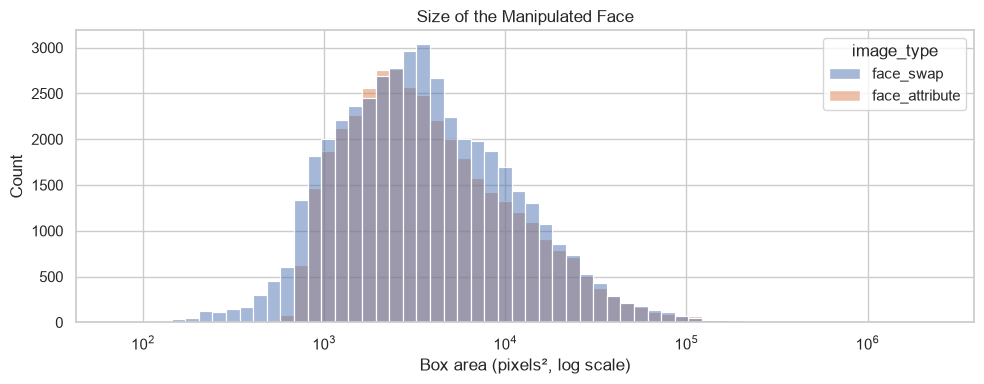

,count,mean,std,min,25%,50%,75%,max
image_type,,,,,,,,
face_attribute,38625.0,7790.0,23500.0,520.0,1764.0,3283.0,7519.0,2303443.0
face_swap,45670.0,7269.0,21781.0,72.0,1575.0,3264.0,7426.0,2303443.0


In [23]:
image_manip["fake_box_area"] = image_manip["fake_image_box"].apply(box_area)
image_manip["image_type"] = np.where(image_manip["fake_cls"].str.contains("face_swap"), "face_swap", "face_attribute")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=image_manip, x="fake_box_area", hue="image_type", bins=60, log_scale=True, ax=ax)
ax.set_title("Size of the Manipulated Face")
ax.set_xlabel("Box area (pixels², log scale)")
plt.tight_layout()
plt.show()

image_manip.groupby("image_type")["fake_box_area"].describe().round(0)

## 7. Image Examples

Red boxes are the manipulated face (`fake_image_box`); blue boxes are all faces found by MTCNN.

Archives available: ['manipulation/infoswap.zip']


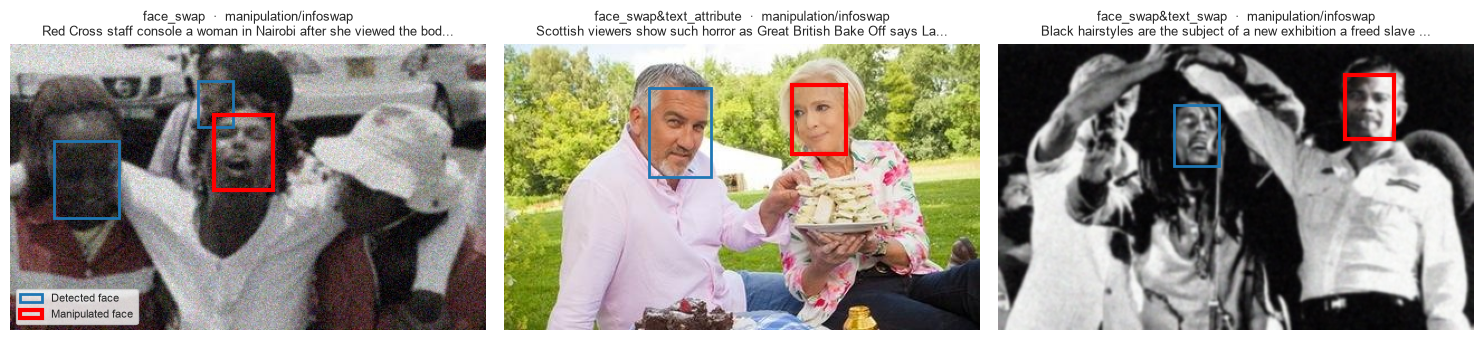

In [24]:
def draw_box(ax, box, color, label=None, linewidth=2):
    if box is None or len(box) != 4:
        return
    x1, y1, x2, y2 = map(float, box)
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                           edgecolor=color, linewidth=linewidth, label=label))


def plot_image_annotations(row, ax):
    ax.imshow(load_hf_image(row["image"]))
    for index, face_box in enumerate(row["mtcnn_boxes"]):
        draw_box(ax, face_box, color="tab:blue", label="Detected face" if index == 0 else None)
    draw_box(ax, row["fake_image_box"], color="red", label="Manipulated face", linewidth=3)
    caption = row["text"] if len(row["text"]) <= 70 else row["text"][:67] + "..."
    ax.set_title(f"{row['fake_cls']}  ·  {row['image_source']}\n{caption}", fontsize=9)
    ax.axis("off")


available = train_df[train_df["image"].apply(archive_for).map(
    lambda a: DOWNLOAD_ARCHIVES or is_archive_cached(a)
)]
print("Archives available:", sorted(available["image"].apply(archive_for).unique()))

samples = available.groupby("fake_cls").sample(1, random_state=RANDOM_STATE).head(6)
n_cols = 3
n_rows = int(np.ceil(len(samples) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows), squeeze=False)
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    plot_image_annotations(row, ax)
for ax in axes.flat[len(samples):]:
    ax.axis("off")
axes.flat[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
# Image resolution of a sample of available images (only cached archives, so this may not represent every source)
size_sample = available.sample(min(300, len(available)), random_state=RANDOM_STATE)
sizes = pd.DataFrame(
    [load_hf_image(p).size for p in size_sample["image"]], columns=["width", "height"]
)
sizes.describe().round(0)

,width,height
count,300.0,300.0
mean,436.0,288.0
std,207.0,182.0
min,256.0,255.0
25%,383.0,256.0
50%,426.0,256.0
75%,426.0,256.0
max,3264.0,3264.0


## 8. Summary of Findings

**Dataset structure**
- 281k image-caption pairs: 208,184 train / 22,126 validation / 50,705 test, with no missing values and no empty captions.
- Each `id` is one source article, shared by its original pair and its manipulated versions. The official splits share no `id`s, so there is no article-level leakage between them. Any extra splitting we do (e.g. CV folds) must also be grouped by `id`.
- Every image has 2 to 5 detected faces (median 2), and images are small (median about 426×256 in the cached sample). Low resolution limits how much pixel-level forensics (ELA, high-pass residuals) can recover.

**Data-quality issues for `02_data_cleaning`**
- **Train repeats genuine pairs.** 51,015 of its 104,092 `orig` rows are exact repeats of the same (id, text, image). This is why train looks 50% genuine while validation and test are about 33%. After removing them, train has 157,169 rows and the same class mix as validation and test.
- Labels are internally consistent: `fake_image_box` is filled exactly when the image is manipulated, and `fake_text_pos` is empty for every row whose caption is unchanged.

**Labels and class balance**
- Fake is the majority class (about 66% in validation and test), the reverse of real-world fraud prevalence. We should also evaluate at a realistic, low share of fakes.
- Two prediction targets come from `fake_cls`: `image_fake` (face_swap / face_attribute) and `text_fake` (text_swap / text_attribute). Text attribute is the rarest manipulation (about 6% of fakes as a single type).

**Signals and risks for feature engineering**
- **Leakage:** the `image` path names the generator folder (`manipulation/infoswap/...` vs `origin/...`). Only pixels may be used.
- **mtcnn_boxes are safe:** they are identical across every row of an `id`, so they were detected on the original image and say nothing about the label.
- **The edited face is not always the main face:** it is the largest face in only 66.7% of image-manipulated samples (2nd largest in 26.4%). Face features must cover every detected face (e.g. the maximum score over faces), not just the main face.
- **Text swap changes caption length:** swapped captions average about 2 words more than unchanged ones (18.7 vs 16.8). This shortcut may not hold outside DGM4, so models should be checked for relying on it.
- **Text attribute is a subtle edit:** usually 1–2 words (median 9% of the caption) are flipped to the opposite sentiment, and the result is often ungrammatical (e.g. "came to [face] [criticism] to tackle corruption"). Sentiment and language-model fluency features are promising. Text swap rewrites about 63% of the words but keeps the person's name, so it needs image-caption consistency features to detect.